# Activity 1: Dataset Preparation
**Unit I – Foundations & Data Preparation**

**Dataset:** Titanic Passenger Dataset  
**Domain:** Transport  
**Source:** [Kaggle Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset)

**Aim:** Inspect, clean and prepare the dataset for future machine learning.

**Kaggle dataset:** `yasserh/titanic-dataset`

## 1. Load Dataset

Load the dataset from the CSV source.

In [10]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(url)

print("Shape:", df.shape)
display(df.head())
display(df.tail())

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


## 2. Inspect Dataset

In [11]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Columns:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Data types:
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare 

The dataset contains passenger details. `survived` is the possible target column.

## 3. Data Types and Statistics

In [12]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns

print("Numerical columns:", list(num_cols))
print("Categorical columns:", list(cat_cols))

display(df[num_cols].describe())
display(df[cat_cols].describe())

Numerical columns: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
Categorical columns: ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,sex,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891,889,891,891,891,203,889,891,891
unique,2,3,3,3,2,7,3,2,2
top,male,S,Third,man,True,C,Southampton,no,True
freq,577,644,491,537,537,59,644,549,537


## 4. Missing Values

In [13]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing)

,Missing Values,Percentage
survived,0,0.00
pclass,0,0.00
sex,0,0.00
age,177,19.87
sibsp,0,0.00
parch,0,0.00
fare,0,0.00
embarked,2,0.22
class,0,0.00
who,0,0.00


## 5. Handle Missing Values

Use median for numerical data, mode for categorical data, and remove `deck` because it has many missing values.

In [14]:
cleaned_df = df.copy()

cleaned_df["age"] = cleaned_df["age"].fillna(cleaned_df["age"].median())

for col in ["embarked", "embark_town"]:
    if col in cleaned_df.columns and cleaned_df[col].isnull().any():
        cleaned_df[col] = cleaned_df[col].fillna(cleaned_df[col].mode()[0])

if "deck" in cleaned_df.columns:
    cleaned_df = cleaned_df.drop(columns=["deck"])

print("Missing values after cleaning:")
display(cleaned_df.isnull().sum())

Missing values after cleaning:


survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

## 6. Duplicates and Consistency

In [15]:
print("Duplicate rows:", cleaned_df.duplicated().sum())

cleaned_df = cleaned_df.drop_duplicates()

text_cols = cleaned_df.select_dtypes(include="object").columns

for col in text_cols:
    cleaned_df[col] = cleaned_df[col].str.strip().str.lower()

print("Shape after cleaning:", cleaned_df.shape)

Duplicate rows: 116
Shape after cleaning: (775, 14)


## 7. Exploratory Data Analysis (EDA)

In [16]:
display(cleaned_df.describe())
display(cleaned_df["sex"].value_counts())

,survived,pclass,age,sibsp,parch,fare
count,775.000000,775.000000,775.000000,775.000000,775.000000,775.000000
mean,0.412903,2.246452,29.581187,0.529032,0.420645,34.878403
std,0.492674,0.853574,13.766359,0.990326,0.840565,52.408474
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,21.000000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,28.000000,0.000000,0.000000,15.900000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,34.197900
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


sex
male      483
female    292
Name: count, dtype: int64

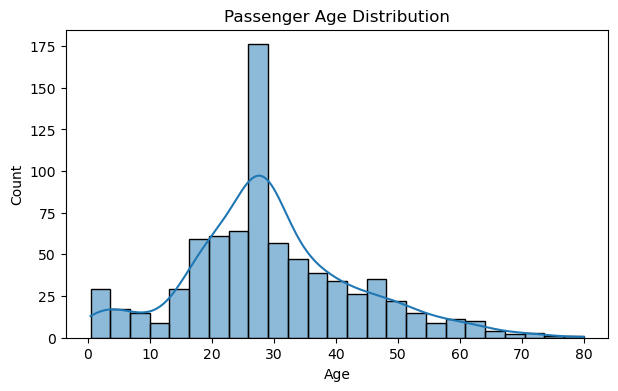

In [17]:
plt.figure(figsize=(7, 4))
sns.histplot(data=cleaned_df, x="age", bins=25, kde=True)
plt.title("Passenger Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

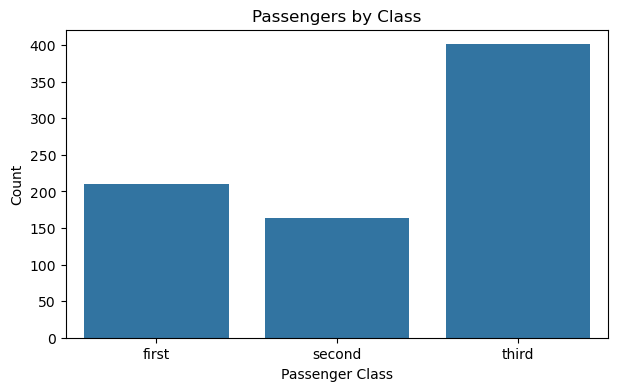

In [18]:
plt.figure(figsize=(7, 4))
sns.countplot(data=cleaned_df, x="class", order=["first", "second", "third"])
plt.title("Passengers by Class")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.show()

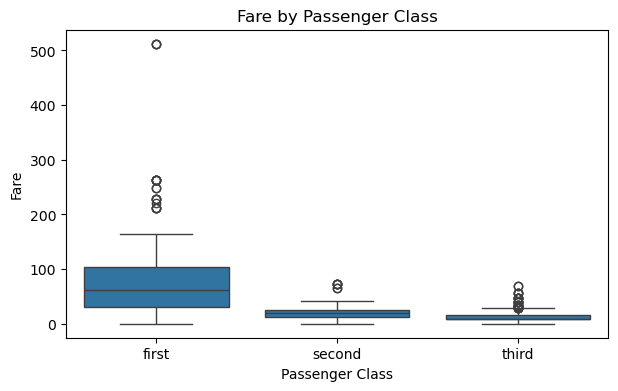

In [19]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=cleaned_df, x="class", y="fare", order=["first", "second", "third"])
plt.title("Fare by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")
plt.show()

**Observations:**
1. The histogram shows passenger age distribution.
2. The bar chart compares passenger classes.
3. The box plot compares fares across classes.

## 8. Encode Categorical Columns

One-hot encoding is used for categorical columns. `alive` is removed because it duplicates `survived`.

In [20]:
encoded_df = cleaned_df.copy()

if "alive" in encoded_df.columns:
    encoded_df = encoded_df.drop(columns=["alive"])

cat_to_encode = encoded_df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

encoded_df = pd.get_dummies(
    encoded_df,
    columns=cat_to_encode,
    dtype=int
)

print("Encoded columns:", cat_to_encode)
print("Shape after encoding:", encoded_df.shape)
display(encoded_df.head())

Encoded columns: ['sex', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alone']
Shape after encoding: (775, 24)


,survived,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_c,embarked_q,...,who_child,who_man,who_woman,adult_male_False,adult_male_True,embark_town_cherbourg,embark_town_queenstown,embark_town_southampton,alone_False,alone_True
0,0,3,22.0,1,0,7.2500,0,1,0,0,...,0,1,0,0,1,0,0,1,1,0
1,1,1,38.0,1,0,71.2833,1,0,1,0,...,0,0,1,1,0,1,0,0,1,0
2,1,3,26.0,0,0,7.9250,1,0,0,0,...,0,0,1,1,0,0,0,1,0,1
3,1,1,35.0,1,0,53.1000,1,0,0,0,...,0,0,1,1,0,0,0,1,1,0
4,0,3,35.0,0,0,8.0500,0,1,0,0,...,0,1,0,0,1,0,0,1,0,1


## 9. Scale Numerical Columns

StandardScaler is used for numerical features. `survived` is not scaled.

In [21]:
scaled_df = encoded_df.copy()

scale_cols = scaled_df.select_dtypes(include=np.number).columns.tolist()
scale_cols = [col for col in scale_cols if col != "survived"]

scaler = StandardScaler()
scaled_df[scale_cols] = scaler.fit_transform(scaled_df[scale_cols])

display(scaled_df.head())

NameError: name 'StandardScaler' is not defined

## 10. Save Prepared Dataset

In [ ]:
print("Final shape:", scaled_df.shape)
print("Missing values:", scaled_df.isnull().sum().sum())
print("Duplicate rows:", scaled_df.duplicated().sum())

display(scaled_df.head())

scaled_df.to_csv("titanic_prepared_dataset.csv", index=False)
print("File saved: titanic_prepared_dataset.csv")

## Conclusion

In this activity, I inspected and cleaned the Titanic dataset. I handled missing values, removed duplicate rows, corrected text formatting, performed EDA, encoded categorical columns and scaled numerical features. Finally, I saved the prepared dataset as a CSV file for future machine learning work.